# Week 2: Data Exploration

also includes week 1 deliverable (table of key columns)

## 1. Loading Files

In [18]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Table with Key Columns

In [20]:

field_name = ['ListingKey', 'ListinContractDate', 'ListPrice',
              'ClosePrice', 'PurchaseContractDate', 'CloseDate',
              'LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger',
              'Latitude', 'Longitude', 'UnparsedAddress']
data_type = ['String', 'DateTime', 'Decimal', 'Decimal',
             'DateTime', 'DateTime', 'Decimal', 'Integer',
             'Integer', 'Decimal', 'Decimal', 'String']
descriptions = ['Primary key and uniquely identifies records',
                'Date Listing Agreement was signed',
                "Seller's asking price at time of listing",
                'Final agreed sale price',
                'Date puchase agreement was signed by both parties, typically 30-45 days before CloseDate',
                'Date transaction officially closed',
                'Interior square footage',
                'Number of bedrooms',
                'Number of bathrooms as an integer',
                'geographic coordinate for mapping',
                'geographic coordinate for mapping',
                'full address as entered by agent']
key_columns = pd.DataFrame.from_dict({'Field Name': field_name, 'Data Type': data_type, 'Description': descriptions})
key_columns

,Field Name,Data Type,Description
0,ListingKey,String,Primary key and uniquely identifies records
1,ListinContractDate,DateTime,Date Listing Agreement was signed
2,ListPrice,Decimal,Seller's asking price at time of listing
3,ClosePrice,Decimal,Final agreed sale price
4,PurchaseContractDate,DateTime,Date puchase agreement was signed by both part...
5,CloseDate,DateTime,Date transaction officially closed
6,LivingArea,Decimal,Interior square footage
7,BedroomsTotal,Integer,Number of bedrooms
8,BathroomsTotalInteger,Integer,Number of bathrooms as an integer
9,Latitude,Decimal,geographic coordinate for mapping


In [21]:
# Create function to load all csv files in a folder

import os
import glob
import pandas as pd

def load_csv_files_from_folder(folder_path):
    """
    Loads all CSV files from the given folder into a list of Pandas DataFrames.
    Each DataFrame is paired with its filename.
    """
    if not os.path.isdir(folder_path):
        raise FileNotFoundError(f"Folder not found: {folder_path}")

    # Find all CSV files in the folder
    csv_files = glob.glob(os.path.join(folder_path, "*.csv"))

    if not csv_files:
        print("No CSV files found in the folder.")
        return []

    dataframes = []
    for file_path in csv_files:
        try:
            df = pd.read_csv(file_path)
            dataframes.append((os.path.basename(file_path), df))
            print(f"Loaded: {os.path.basename(file_path)} ({len(df)} rows)")
        except Exception as e:
            print(f"Error loading {file_path}: {e}")

    return dataframes

In [22]:
# Load 6 months of data
data_list = load_csv_files_from_folder("/content/drive/MyDrive/IDX Data Science")

Loaded: CRMLSSold202603.csv (23372 rows)
Loaded: CRMLSSold202508.csv (22972 rows)
Loaded: CRMLSSold202507.csv (23646 rows)
Loaded: CRMLSSold202505.csv (23154 rows)
Loaded: CRMLSSold202604.csv (24261 rows)
Loaded: CRMLSSold202511.csv (19088 rows)
Loaded: CRMLSSold202504.csv (23262 rows)
Loaded: CRMLSSold202512.csv (20538 rows)
Loaded: CRMLSSold202509.csv (22443 rows)


/tmp/ipykernel_2311/2863559646.py:25: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


Loaded: CRMLSSold202506.csv (22883 rows)


/tmp/ipykernel_2311/2863559646.py:25: DtypeWarning: Columns (4,74) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


Loaded: CRMLSSold202601.csv (16487 rows)
Loaded: CRMLSSold202602.csv (19010 rows)
Loaded: CRMLSSold202510.csv (23233 rows)
Loaded: CRMLSSold202503.csv (21445 rows)
Loaded: CRMLSSold202502.csv (18702 rows)


Note: will address column discrepancy type in data cleaning stage

In [23]:
# Combine into dataframe
combined = pd.concat([df for __,df in data_list], ignore_index=True)
#combined.head(10)

In [24]:
# Filtering Data
print(f"Number of Rows before Restriction: {len(combined)}")

#Restrict Property Type to Residential and SubType to Single-Family Residence
residential = combined[combined['PropertyType'] == 'Residential']
print(f"Number of Rows after filtering by PropertyType: {len(residential)}")

#Restrict Property SubType to Single-Family Residence
filtered = residential[residential['PropertySubType'] == 'SingleFamilyResidence']
print(f"Number of Rows after full Restriction: {len(filtered)}")



Number of Rows before Restriction: 324496
Number of Rows after filtering by PropertyType: 216835
Number of Rows after full Restriction: 162567


# Exploratory Data Analysis

## Summary Statistics

In [25]:
eda_cols = ['ClosePrice', 'LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeAcres', 'LotSizeSquareFeet']
filtered[eda_cols].describe()

,ClosePrice,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeAcres,LotSizeSquareFeet
count,1.625670e+05,162480.000000,162567.000000,162548.000000,159735.000000,1.597340e+05
mean,1.330335e+06,2044.902302,3.488334,2.630183,14.356563,3.587556e+05
std,7.598653e+06,1038.853750,0.971468,1.135957,811.596613,1.772486e+07
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00
25%,6.250000e+05,1384.000000,3.000000,2.000000,0.130000,5.663000e+03
50%,8.900000e+05,1816.000000,3.000000,2.000000,0.167100,7.280000e+03
75%,1.421204e+06,2437.000000,4.000000,3.000000,0.240000,1.045400e+04
max,9.895000e+08,56500.000000,45.000000,45.000000,127631.000000,2.087221e+09


## Plotting Distributions of Each Variable

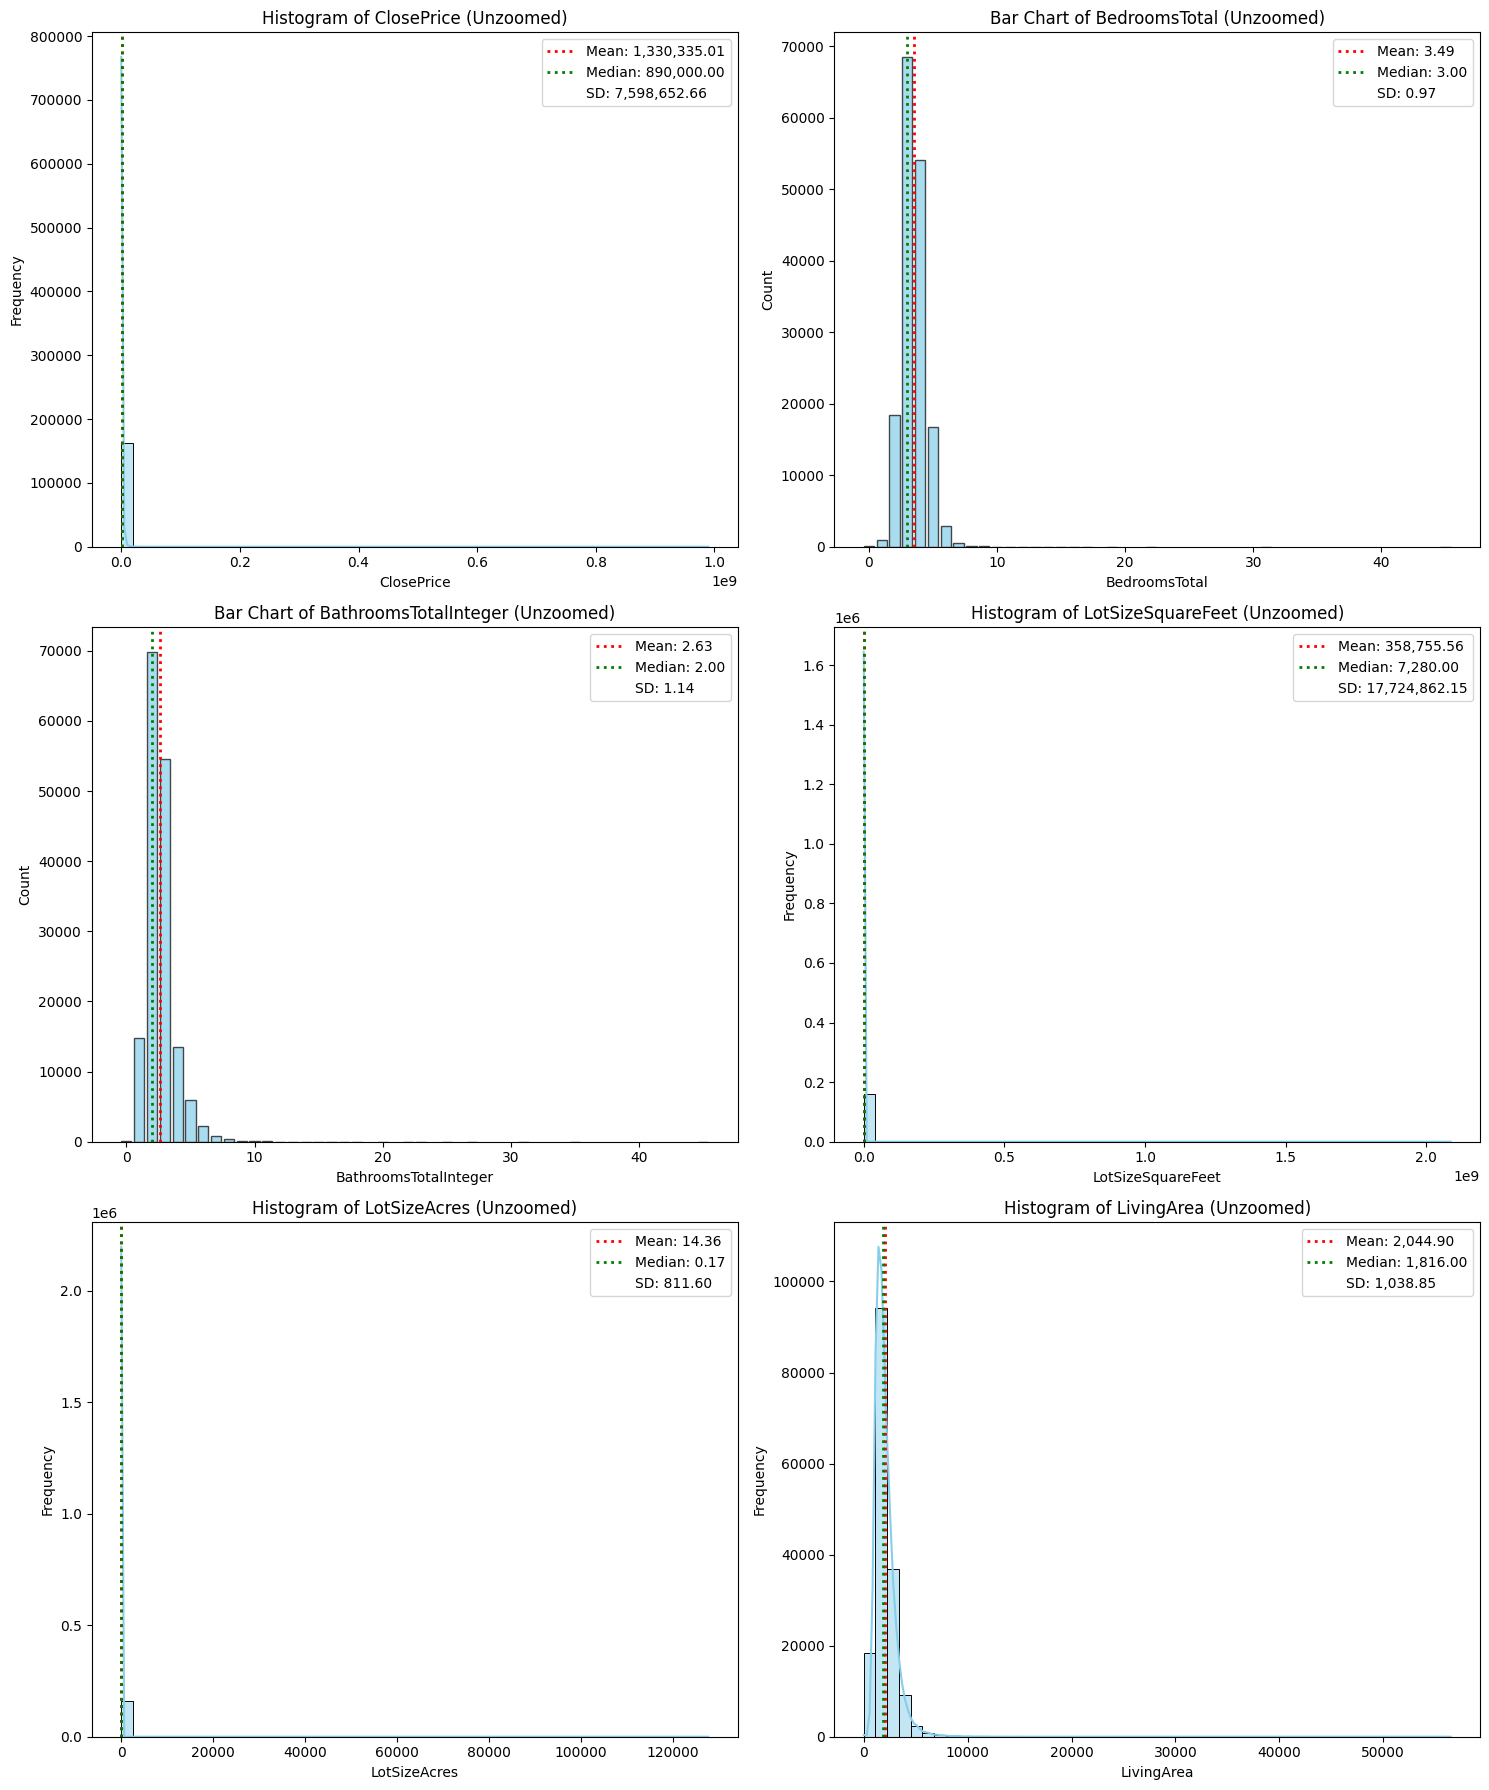

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set up a 3x2 grid of subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 18))
axes = axes.flatten()

columns_to_plot = [
    'ClosePrice', 'BedroomsTotal', 'BathroomsTotalInteger',
    'LotSizeSquareFeet', 'LotSizeAcres', 'LivingArea'
]

for i, col in enumerate(columns_to_plot):
    plot_data = filtered[col].dropna()
    mean_val = plot_data.mean()
    median_val = plot_data.median()
    std_val = plot_data.std()

    if col in ['BedroomsTotal', 'BathroomsTotalInteger']:
        # Group by value and calculate counts to create a clean bar chart
        value_counts = plot_data.value_counts().sort_index()
        axes[i].bar(value_counts.index, value_counts.values, color='skyblue', edgecolor='black', alpha=0.7)
        axes[i].set_title(f'Bar Chart of {col} (Unzoomed)')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Count')
    else:
        # For continuous variables, use histplot
        sns.histplot(plot_data, bins=50, kde=True, ax=axes[i], color='skyblue')
        axes[i].set_title(f'Histogram of {col} (Unzoomed)')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frequency')

    # Add vertical dotted lines for mean and median
    axes[i].axvline(mean_val, color='red', linestyle=':', linewidth=2, label=f'Mean: {mean_val:,.2f}')
    axes[i].axvline(median_val, color='green', linestyle=':', linewidth=2, label=f'Median: {median_val:,.2f}')

    # Add dummy plot or text to place SD in the legend
    axes[i].plot([], [], ' ', label=f'SD: {std_val:,.2f}')
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()

Plotting the data without handline outliers does not seem to make very useful visualizations, after zooming data we can still see the influence of outliers however can also more clearly visualize the general distribution.


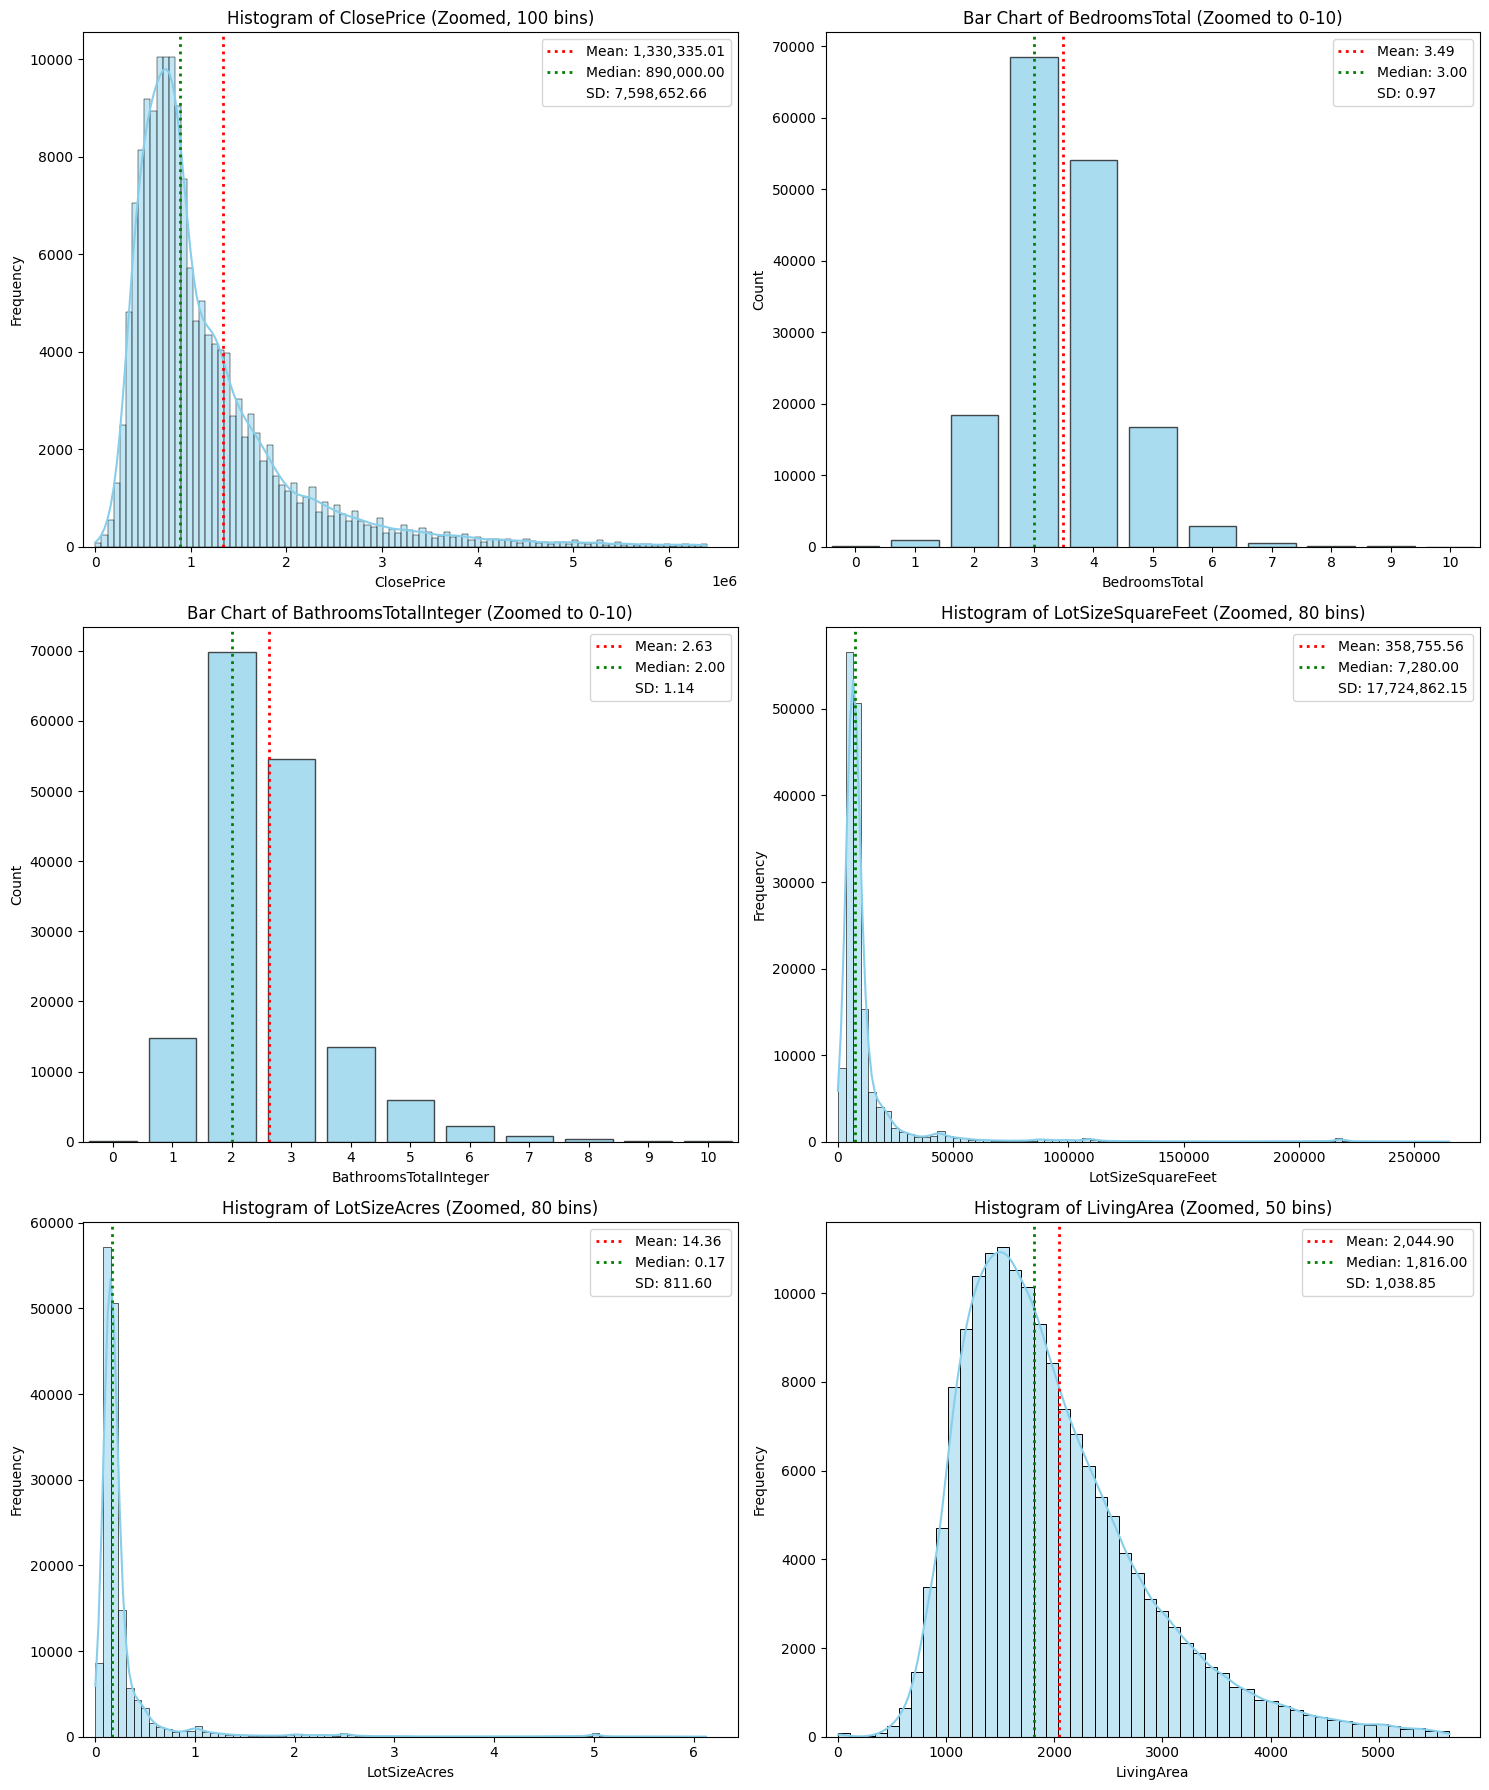

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set up a 3x2 grid of subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 18))
axes = axes.flatten()

columns_to_plot = [
    'ClosePrice', 'BedroomsTotal', 'BathroomsTotalInteger',
    'LotSizeSquareFeet', 'LotSizeAcres', 'LivingArea'
]

for i, col in enumerate(columns_to_plot):
    plot_data = filtered[col].dropna()
    mean_val = plot_data.mean()
    median_val = plot_data.median()
    std_val = plot_data.std()

    if col == 'ClosePrice':
        limit = plot_data.quantile(0.99)
        zoomed_data = plot_data[plot_data <= limit]
        sns.histplot(zoomed_data, bins=100, kde=True, ax=axes[i], color='skyblue')
        axes[i].set_xlim(-limit * 0.02, limit * 1.05)
        axes[i].set_title('Histogram of ClosePrice (Zoomed, 100 bins)')

    elif col in ['BedroomsTotal', 'BathroomsTotalInteger']:
        # Filter data to the 0-10 range
        zoomed_data = plot_data[(plot_data >= 0) & (plot_data <= 10)]
        value_counts = zoomed_data.value_counts().sort_index()

        # Create a bar chart for discrete zoom
        axes[i].bar(value_counts.index, value_counts.values, color='skyblue', edgecolor='black', alpha=0.7)
        axes[i].set_xlim(-0.5, 10.5)
        axes[i].set_xticks(range(11))
        axes[i].set_title(f'Bar Chart of {col} (Zoomed to 0-10)')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Count')

    elif col == 'LotSizeSquareFeet':
        limit = plot_data.quantile(0.99)
        zoomed_data = plot_data[plot_data <= limit]
        sns.histplot(zoomed_data, bins=80, kde=True, ax=axes[i], color='skyblue')
        axes[i].set_xlim(-limit * 0.02, limit * 1.05)
        axes[i].set_title('Histogram of LotSizeSquareFeet (Zoomed, 80 bins)')

    elif col == 'LotSizeAcres':
        limit = plot_data.quantile(0.99)
        zoomed_data = plot_data[plot_data <= limit]
        sns.histplot(zoomed_data, bins=80, kde=True, ax=axes[i], color='skyblue')
        axes[i].set_xlim(-limit * 0.02, limit * 1.05)
        axes[i].set_title('Histogram of LotSizeAcres (Zoomed, 80 bins)')

    elif col == 'LivingArea':
        limit = plot_data.quantile(0.99)
        zoomed_data = plot_data[plot_data <= limit]
        sns.histplot(zoomed_data, bins=50, kde=True, ax=axes[i], color='skyblue')
        axes[i].set_xlim(-limit * 0.02, limit * 1.05)
        axes[i].set_title('Histogram of LivingArea (Zoomed, 50 bins)')

    if col not in ['BedroomsTotal', 'BathroomsTotalInteger']:
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frequency')

    # Add vertical dotted lines for overall mean and median
    axes[i].axvline(mean_val, color='red', linestyle=':', linewidth=2, label=f'Mean: {mean_val:,.2f}')
    axes[i].axvline(median_val, color='green', linestyle=':', linewidth=2, label=f'Median: {median_val:,.2f}')

    # Add SD to the legend
    axes[i].plot([], [], ' ', label=f'SD: {std_val:,.2f}')
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()

Most of the distributions seem to be right-skewed, and Lot Size and Close Price have wider spreads as well.

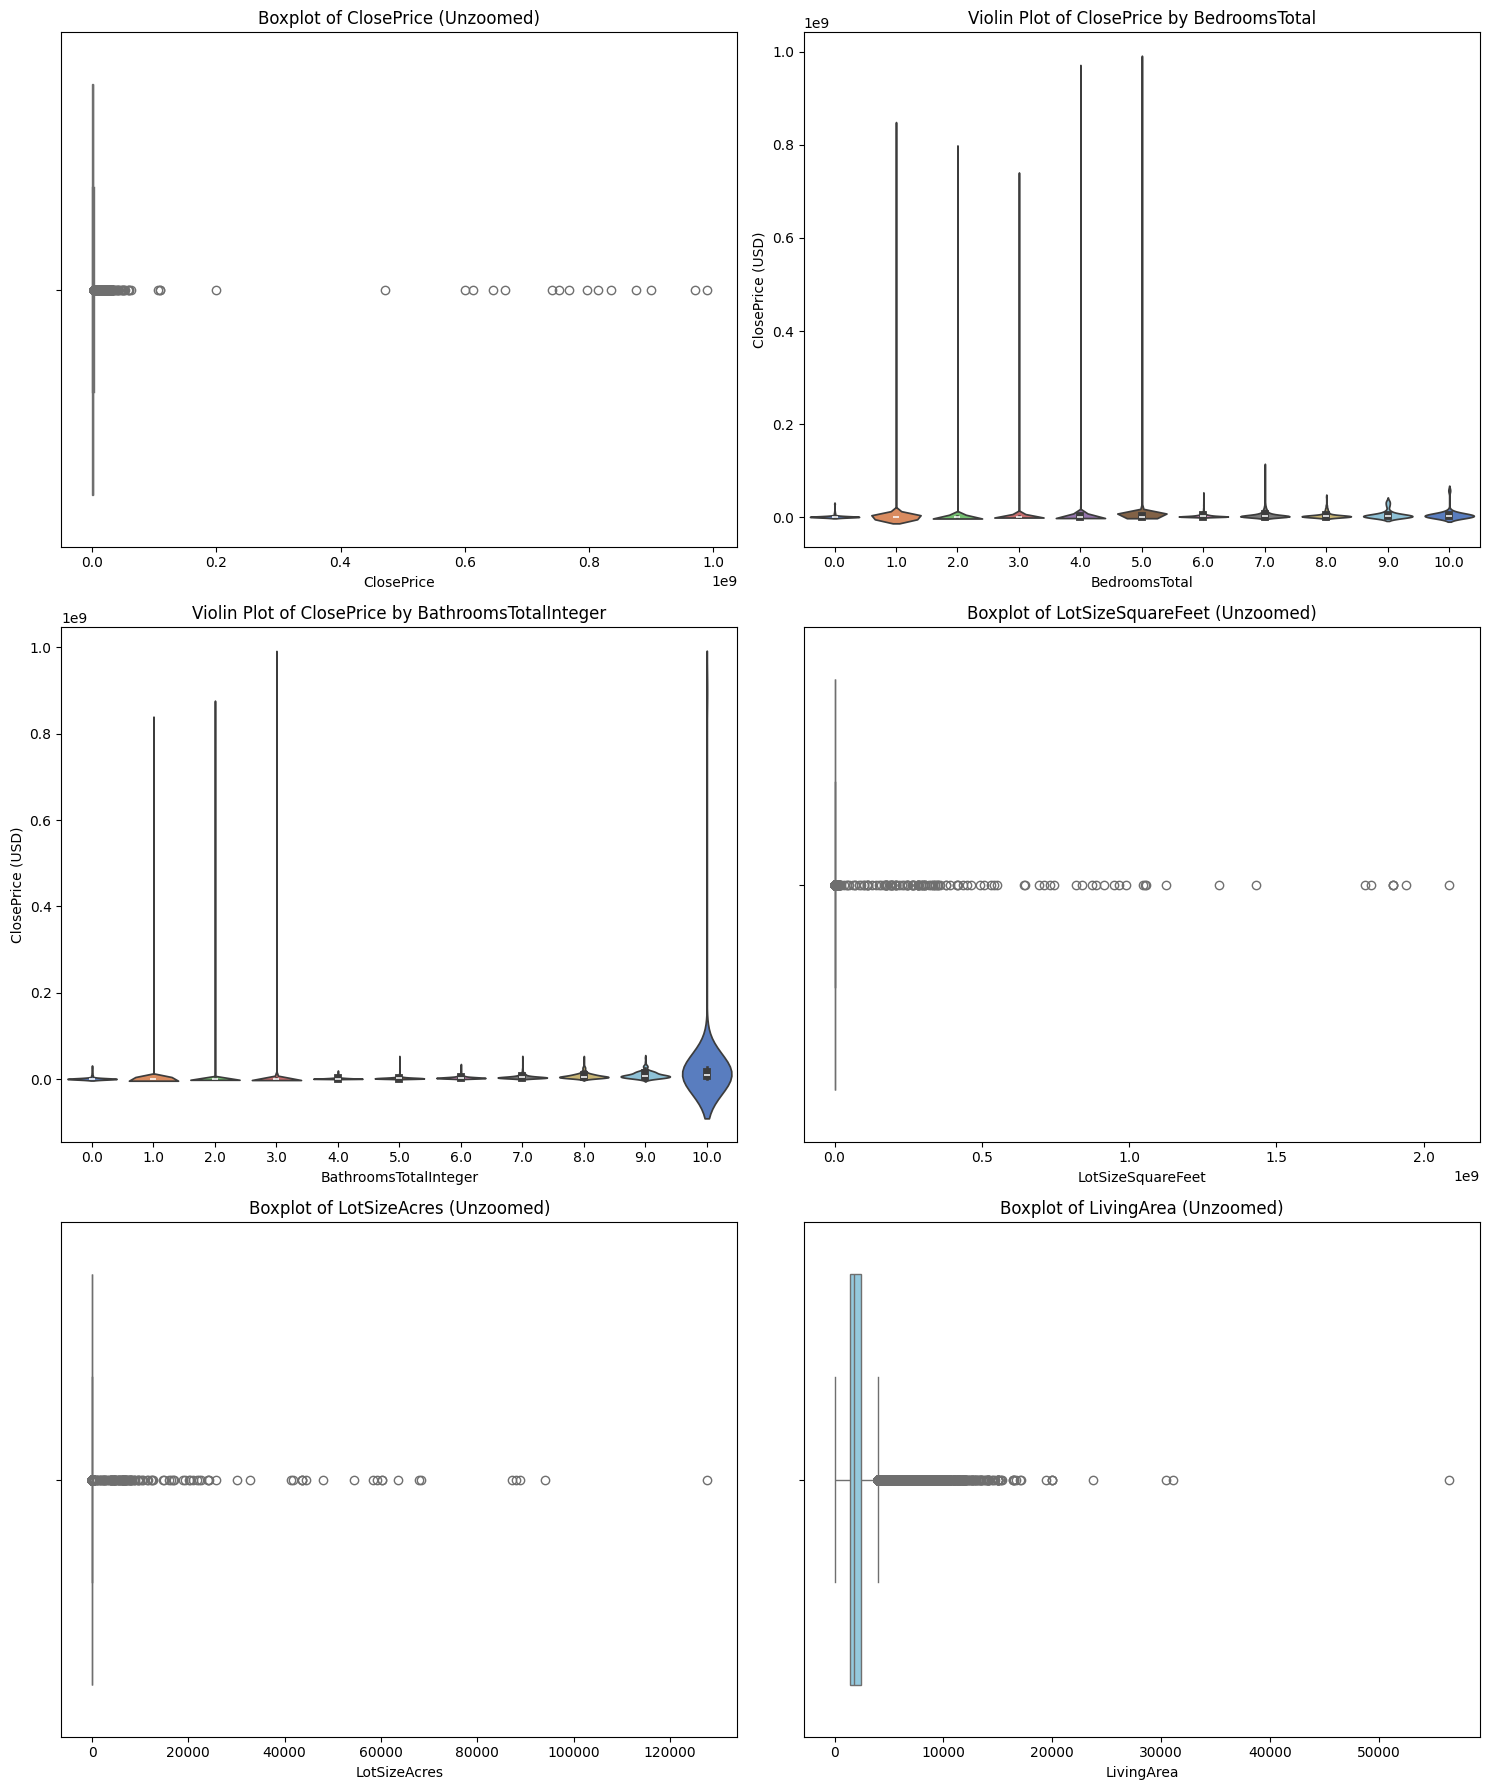

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set up a 3x2 grid of subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 18))
axes = axes.flatten()

columns_to_plot = [
    'ClosePrice', 'BedroomsTotal', 'BathroomsTotalInteger',
    'LotSizeSquareFeet', 'LotSizeAcres', 'LivingArea'
]

for i, col in enumerate(columns_to_plot):
    plot_data = filtered[col].dropna()

    if col in ['BedroomsTotal', 'BathroomsTotalInteger']:
        # Violin plot using the discrete counts as categories
        # Filter values to realistic categories (e.g., 0 to 10) for better visualization
        cat_data = filtered[filtered[col].between(0, 10)].dropna(subset=[col, 'ClosePrice'])
        sns.violinplot(x=col, y='ClosePrice', hue=col, data=cat_data, ax=axes[i], palette='muted', legend=False)
        axes[i].set_title(f'Violin Plot of ClosePrice by {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('ClosePrice (USD)')
    else:
        # Boxplot for continuous variables (unzoomed)
        sns.boxplot(x=plot_data, ax=axes[i], color='skyblue')
        axes[i].set_title(f'Boxplot of {col} (Unzoomed)')
        axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

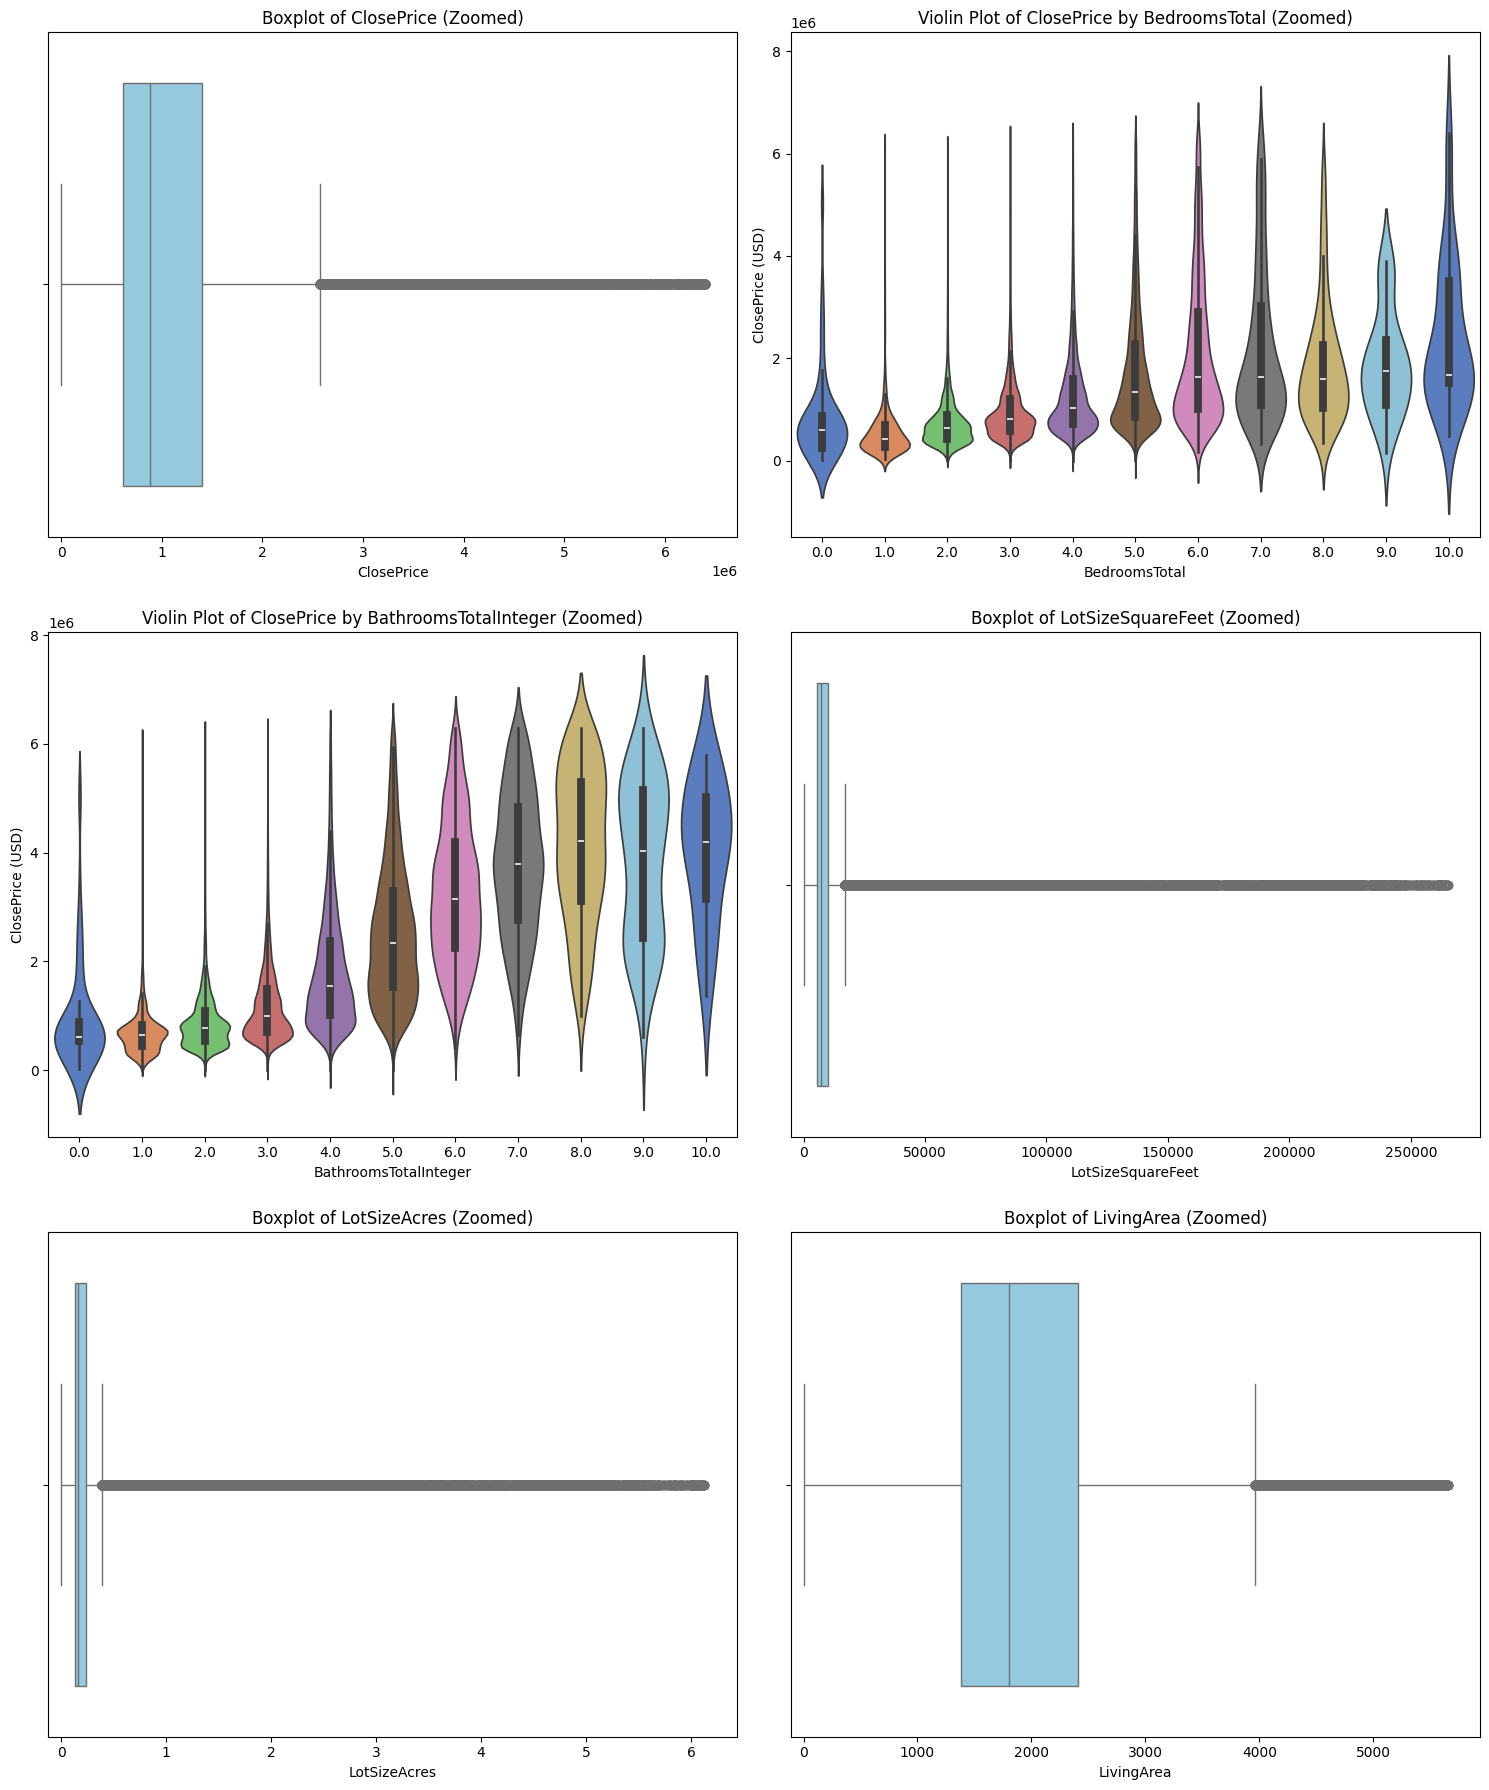

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set up a 3x2 grid of subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 18))
axes = axes.flatten()

columns_to_plot = [
    'ClosePrice', 'BedroomsTotal', 'BathroomsTotalInteger',
    'LotSizeSquareFeet', 'LotSizeAcres', 'LivingArea'
]

for i, col in enumerate(columns_to_plot):
    plot_data = filtered[col].dropna()

    if col in ['BedroomsTotal', 'BathroomsTotalInteger']:
        # Zoomed Violin plot focusing on values between 0 and 10, with ClosePrice zoomed to 99th percentile
        cat_data = filtered[filtered[col].between(0, 10)].dropna(subset=[col, 'ClosePrice'])
        price_limit = cat_data['ClosePrice'].quantile(0.99)
        zoomed_cat_data = cat_data[cat_data['ClosePrice'] <= price_limit]

        sns.violinplot(x=col, y='ClosePrice', hue=col, data=zoomed_cat_data, ax=axes[i], palette='muted', legend=False)
        axes[i].set_title(f'Violin Plot of ClosePrice by {col} (Zoomed)')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('ClosePrice (USD)')
    else:
        # Zoomed Boxplot for continuous variables (using 99th percentile for bounds)
        limit = plot_data.quantile(0.99)
        zoomed_plot_data = plot_data[plot_data <= limit]

        sns.boxplot(x=zoomed_plot_data, ax=axes[i], color='skyblue')
        axes[i].set_xlim(-limit * 0.02, limit * 1.05)
        axes[i].set_title(f'Boxplot of {col} (Zoomed)')
        axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()


## Plotting each variable against ClosePrice and Log Close Price


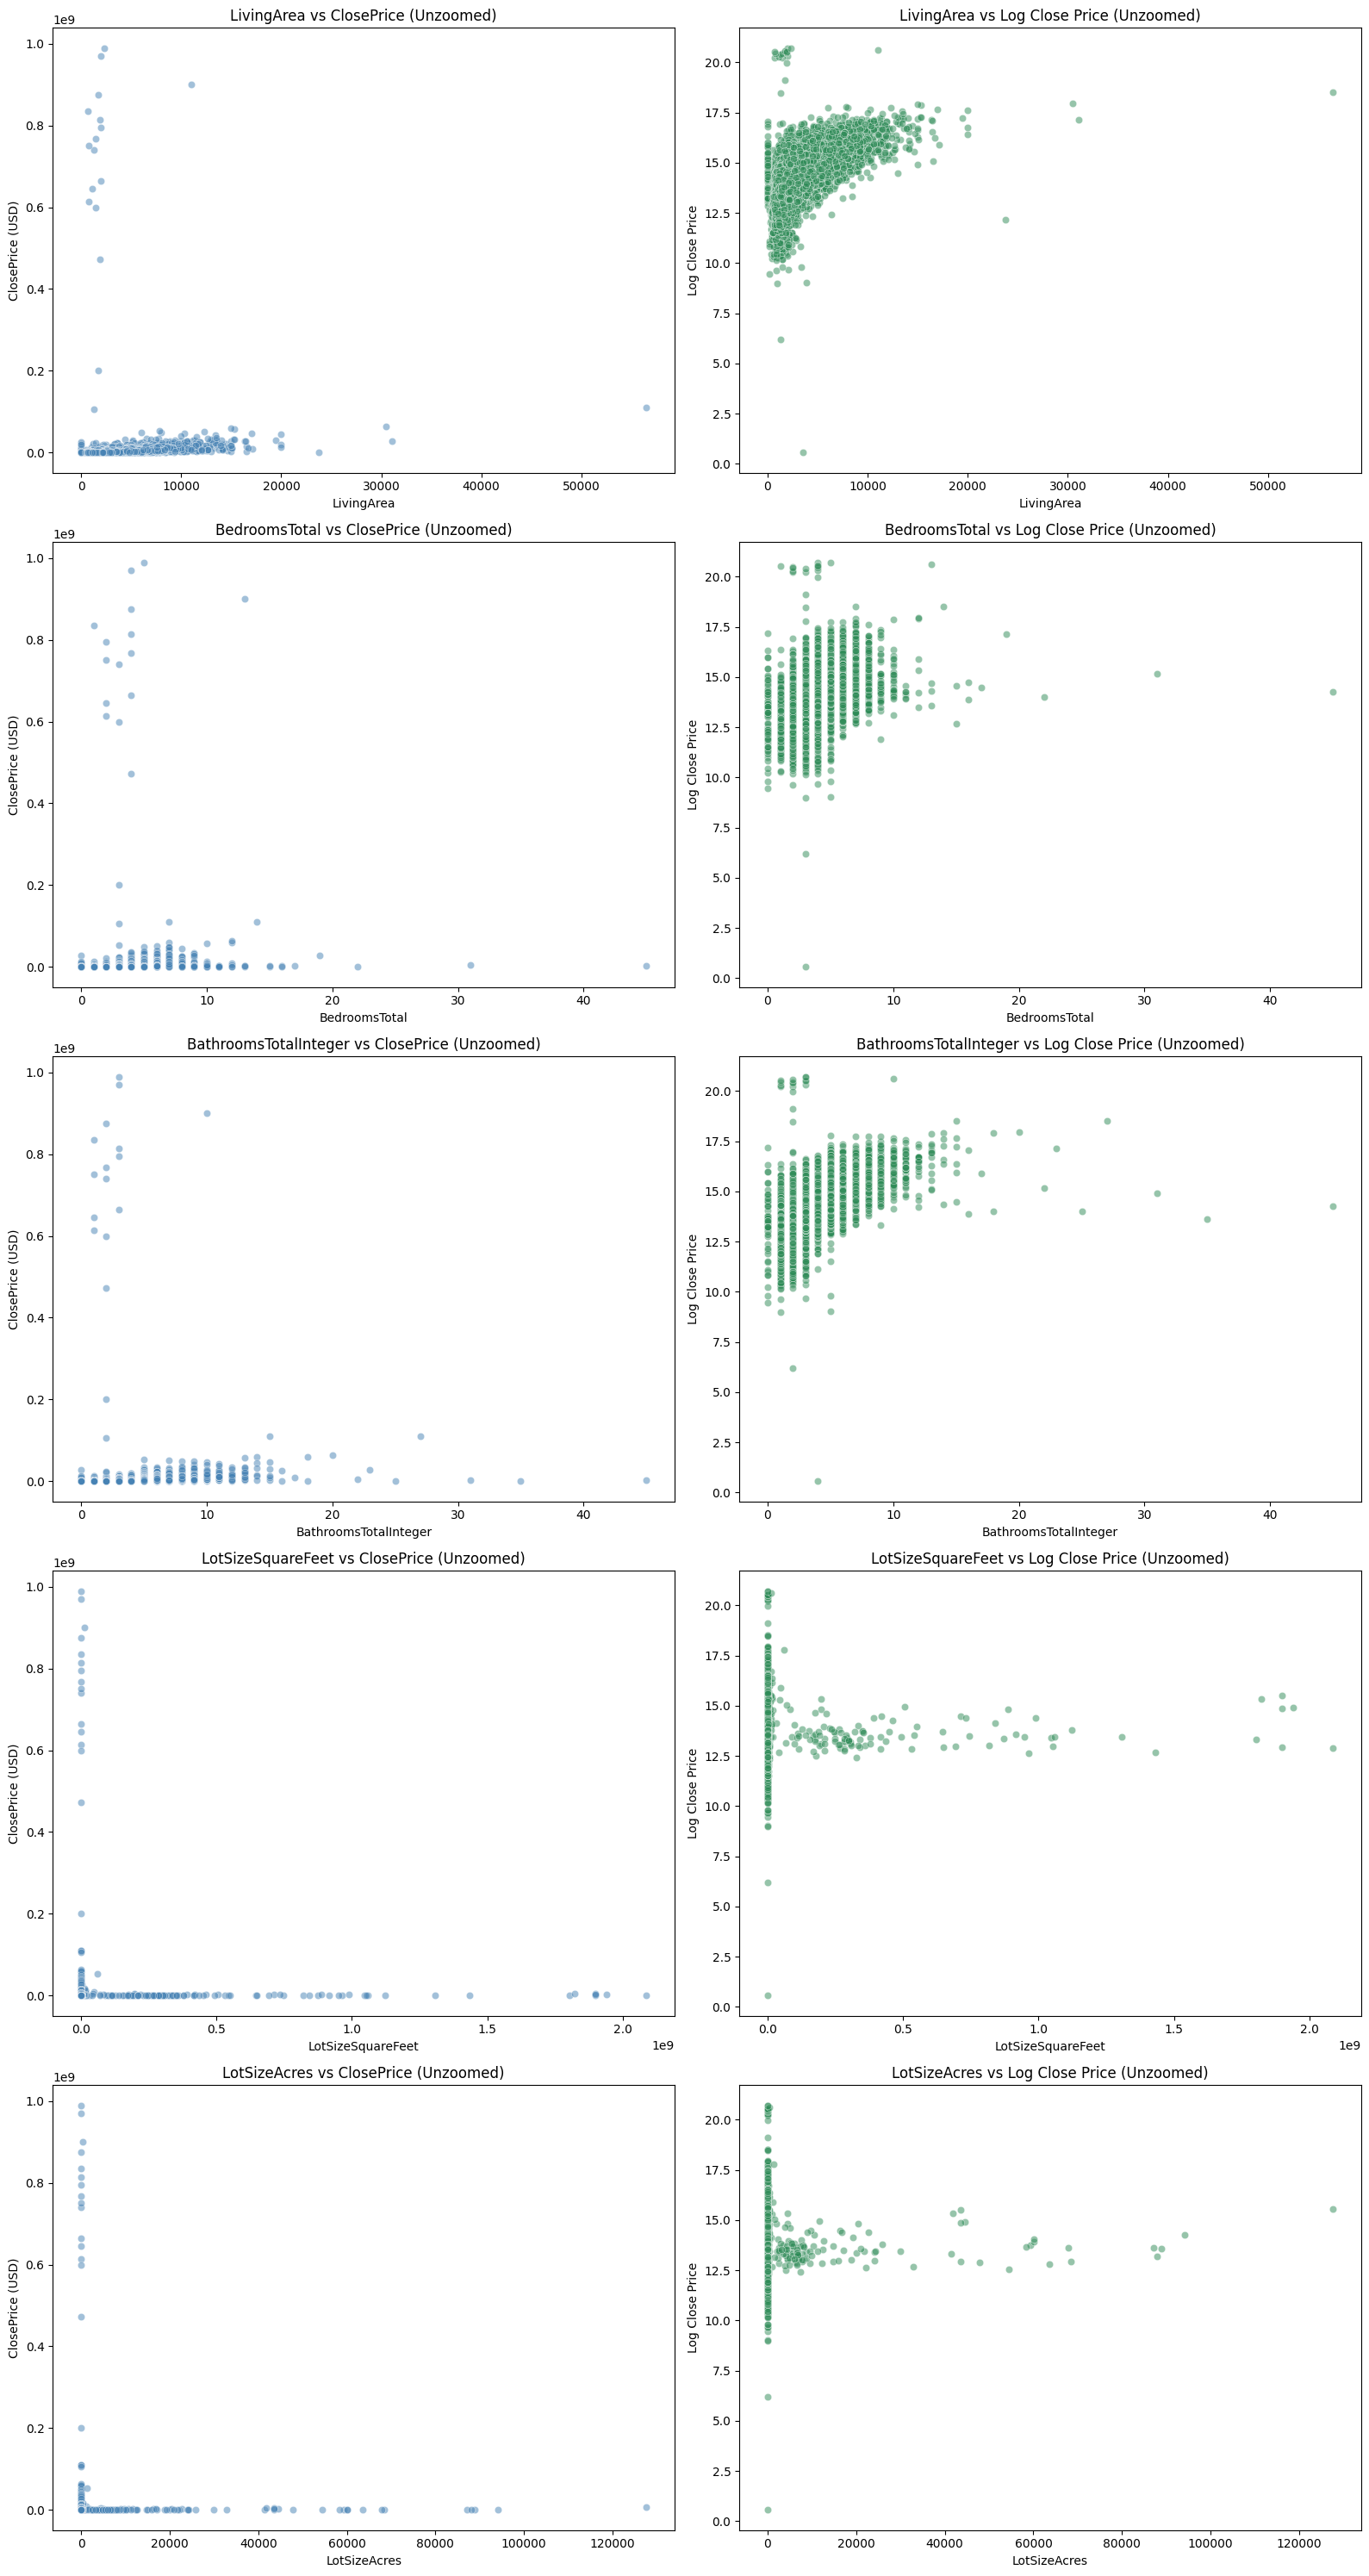

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define the variables to plot against ClosePrice and Log Close Price
other_variables = ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'LotSizeAcres']

# Filter out 0 or negative prices to avoid math domain errors when taking log
valid_data = filtered[filtered['ClosePrice'] > 0].copy()
valid_data['LogClosePrice'] = np.log(valid_data['ClosePrice'])

# Create a 5x2 subplot grid
fig, axes = plt.subplots(5, 2, figsize=(16, 30))

for i, var in enumerate(other_variables):
    # Drop NaNs in the current pair of variables for plotting
    plot_df = valid_data.dropna(subset=[var, 'ClosePrice'])

    # Column 1: Variable vs ClosePrice (Unzoomed)
    sns.scatterplot(data=plot_df, x=var, y='ClosePrice', ax=axes[i, 0], alpha=0.5, color='steelblue')
    axes[i, 0].set_title(f'{var} vs ClosePrice (Unzoomed)')
    axes[i, 0].set_xlabel(var)
    axes[i, 0].set_ylabel('ClosePrice (USD)')

    # Column 2: Variable vs Log Close Price (Unzoomed)
    sns.scatterplot(data=plot_df, x=var, y='LogClosePrice', ax=axes[i, 1], alpha=0.5, color='seagreen')
    axes[i, 1].set_title(f'{var} vs Log Close Price (Unzoomed)')
    axes[i, 1].set_xlabel(var)
    axes[i, 1].set_ylabel('Log Close Price')

plt.tight_layout()
plt.show()

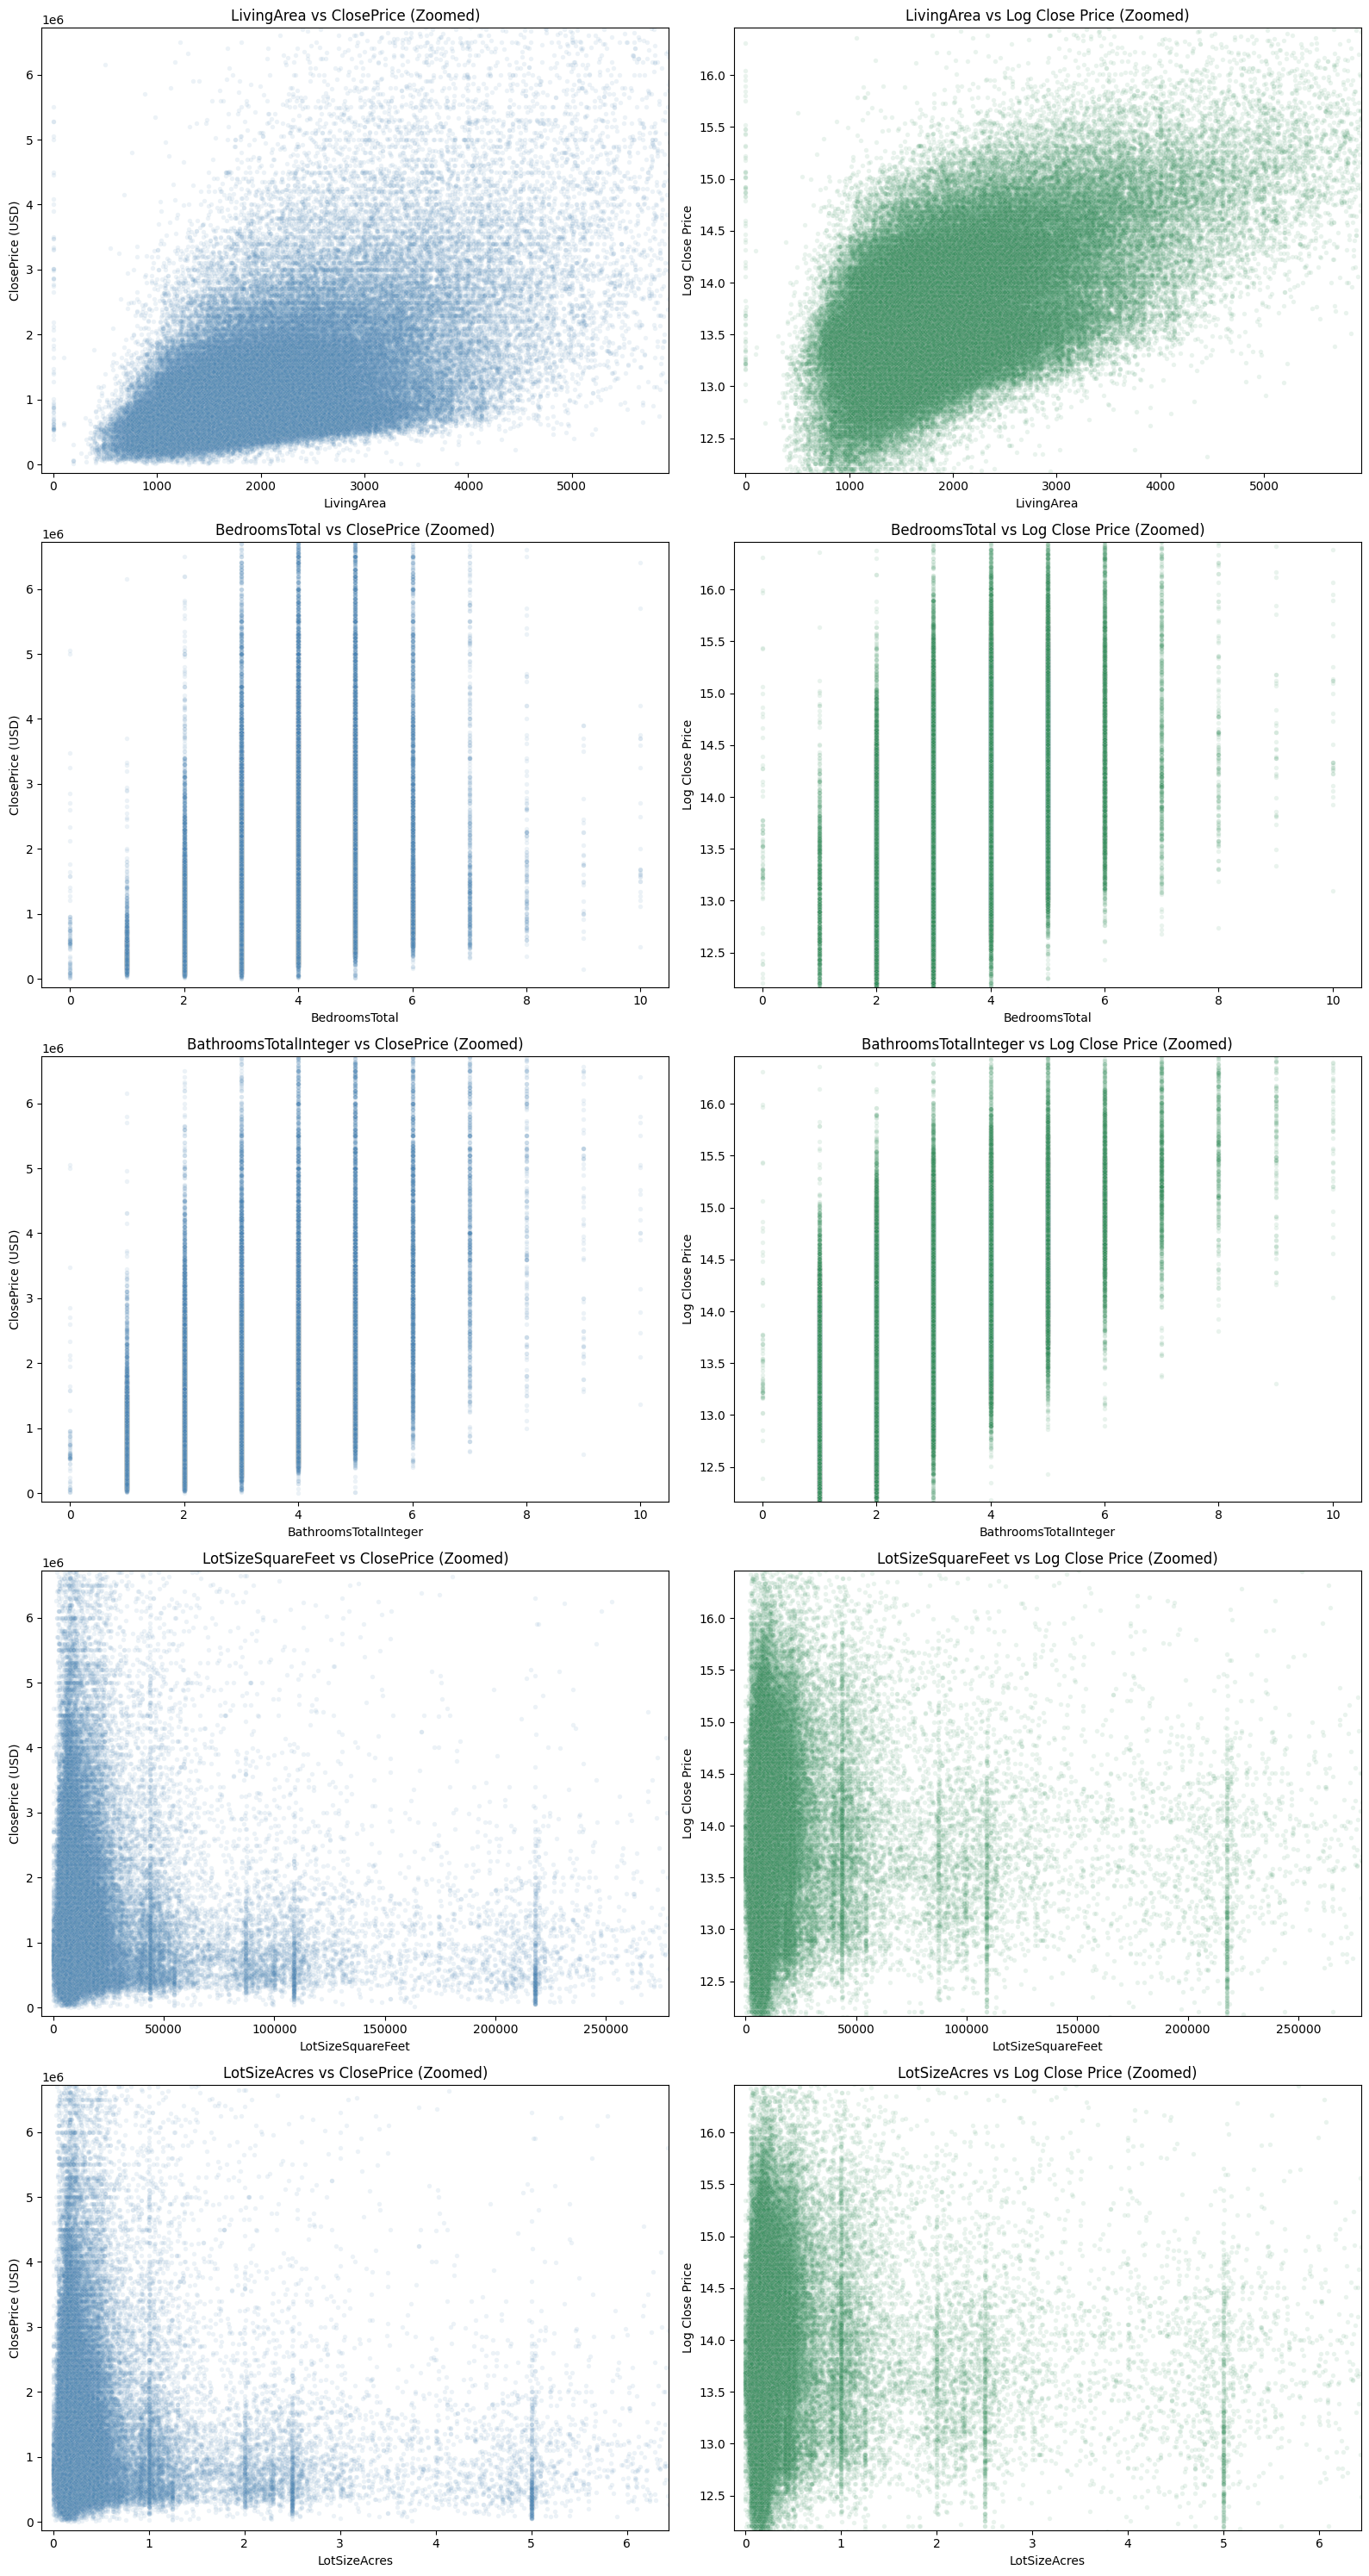

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Define variables to plot
other_variables = ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'LotSizeAcres']

# Filter valid positive prices for log transformation
valid_data = filtered[filtered['ClosePrice'] > 0].copy()
valid_data['LogClosePrice'] = np.log(valid_data['ClosePrice'])

# Establish global ClosePrice limits using 99th percentile
price_limit = valid_data['ClosePrice'].quantile(0.99)
log_price_limit = valid_data['LogClosePrice'].quantile(0.99)
log_price_min = valid_data['LogClosePrice'].quantile(0.01) # lower bound for log price to avoid long bottom tail

# Create a 5x2 subplot grid
fig, axes = plt.subplots(5, 2, figsize=(16, 30))

for i, var in enumerate(other_variables):
    # Drop NaNs
    plot_df = valid_data.dropna(subset=[var, 'ClosePrice'])

    # Establish variable-specific limits (using 99th percentile for continuous, exact limits for discrete)
    if var in ['BedroomsTotal', 'BathroomsTotalInteger']:
        x_min, x_max = -0.5, 10.5
    else:
        x_min = -plot_df[var].quantile(0.99) * 0.02
        x_max = plot_df[var].quantile(0.99) * 1.05

    # Column 1: Variable vs ClosePrice (Zoomed)
    sns.scatterplot(data=plot_df, x=var, y='ClosePrice', ax=axes[i, 0], alpha=0.1, s=15, color='steelblue')
    axes[i, 0].set_xlim(x_min, x_max)
    axes[i, 0].set_ylim(-price_limit * 0.02, price_limit * 1.05)
    axes[i, 0].set_title(f'{var} vs ClosePrice (Zoomed)')
    axes[i, 0].set_xlabel(var)
    axes[i, 0].set_ylabel('ClosePrice (USD)')

    # Column 2: Variable vs Log Close Price (Zoomed)
    sns.scatterplot(data=plot_df, x=var, y='LogClosePrice', ax=axes[i, 1], alpha=0.1, s=15, color='seagreen')
    axes[i, 1].set_xlim(x_min, x_max)
    axes[i, 1].set_ylim(log_price_min - 0.2, log_price_limit * 1.05)
    axes[i, 1].set_title(f'{var} vs Log Close Price (Zoomed)')
    axes[i, 1].set_xlabel(var)
    axes[i, 1].set_ylabel('Log Close Price')

plt.tight_layout()
plt.show()

### Correlation Heatmap

Text(0.5, 1.0, 'Correlation Heatmap - Close Price')

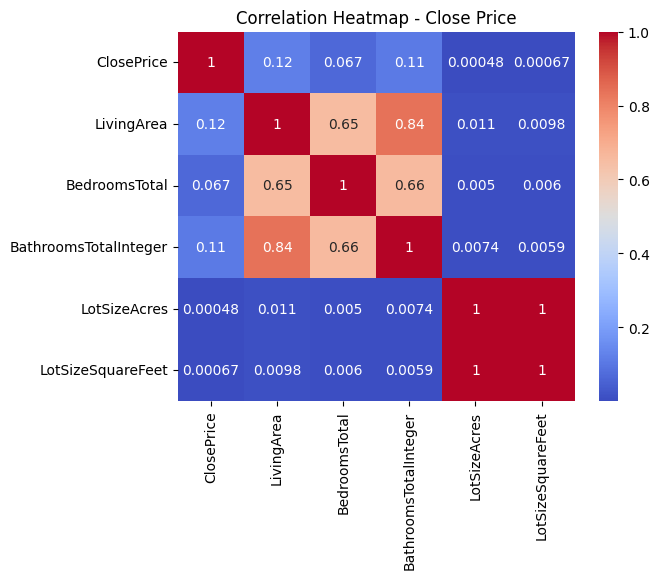

In [36]:
heatmap_filtered = filtered[['ClosePrice', 'LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeAcres', 'LotSizeSquareFeet']].copy()
sns.heatmap(data=heatmap_filtered.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap - Close Price')

/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


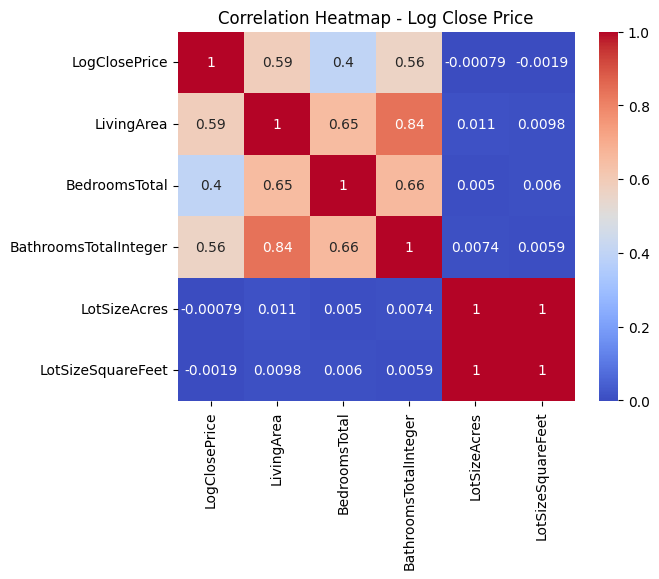

In [37]:
heatmap_filtered_2 = filtered[['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeAcres', 'LotSizeSquareFeet']].copy()
heatmap_filtered_2['LogClosePrice'] = np.log(filtered['ClosePrice'])

# Rearrange columns so 'LogClosePrice' is first
cols = ['LogClosePrice'] + [col for col in heatmap_filtered_2.columns if col != 'LogClosePrice']
heatmap_filtered_2 = heatmap_filtered_2[cols]

sns.heatmap(data=heatmap_filtered_2.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap - Log Close Price')
plt.show()